<a href="https://colab.research.google.com/github/knight19720208ui/AI/blob/main/6_Reconocimiento_Facial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconocimiento Facial: de Haarcascade a DeepFace

Cuaderno didáctico para Google Colab. Cubre la evolución del reconocimiento facial desde los métodos clásicos (Haarcascade, 2001) hasta los modernos basados en deep learning (DeepFace, face_recognition, MediaPipe).

## Lo que aprenderán

- Detección facial clásica con Haarcascade (Viola-Jones)
- Detección con redes neuronales (DNN de OpenCV)
- Malla facial de 468 puntos con MediaPipe
- Generación de embeddings faciales con face_recognition
- Análisis completo (edad, emoción, género) con DeepFace
- Comparación de rostros por similitud coseno

## Convenciones del cuaderno

- **[PY]** cada ejemplo genera rostros sintéticos con NumPy o usa imágenes de prueba.
- Cada ejemplo tiene tres celdas: (a) contexto pedagógico, (b) código, (c) gráfica separada.
- Comentarios en español explicando cada paso clave.
- Antes de los ejemplos hay un glosario único de conceptos.

## Notas importantes

- Algunas bibliotecas (face_recognition, deepface) requieren instalación pesada; pueden tardar 2-3 minutos en Colab.
- Para los ejemplos con rostros reales, ofrecemos descargar imágenes de prueba o usar la cámara web.


## Configuración inicial

Ejecuten la siguiente celda **antes de empezar**. Instala las librerías necesarias y carga los imports básicos. Algunas bibliotecas específicas se instalan en sus ejemplos correspondientes.

Librerías base:
- **numpy**: cálculo numérico y generación de rostros sintéticos.
- **opencv-python** (`cv2`): procesamiento de imágenes y detector Haarcascade/DNN.
- **matplotlib**: visualización de imágenes.
- **plotly**: gráficas interactivas.

Bibliotecas especializadas (se instalan en su ejemplo):
- **mediapipe**: malla facial de Google.
- **face_recognition**: embeddings faciales basados en dlib.
- **deepface**: análisis de edad, emoción, género.


In [1]:
# === Instalación de dependencias base ===
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "numpy", "opencv-python", "opencv-python-headless",
                       "matplotlib", "plotly", "pandas"])

# === Imports globales ===
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib import rc
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from IPython.display import HTML, display
import warnings
warnings.filterwarnings('ignore')

# Configuración de matplotlib
rc('animation', html='jshtml')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# Reproducibilidad
np.random.seed(42)

# Funciones auxiliares
def mostrar_imagen(img, titulo='Imagen', cmap=None, figsize=(6, 6)):
    """Muestra una imagen con matplotlib. Acepta BGR (OpenCV) o GRIS."""
    if len(img.shape) == 3 and img.shape[2] == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img, cmap=cmap)
    ax.set_title(titulo)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def mostrar_multiples(imagenes, titulos, cols=3, cmap=None):
    """Muestra varias imágenes en una grilla."""
    n = len(imagenes)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = axes[np.newaxis, :]
    elif cols == 1:
        axes = axes[:, np.newaxis]
    for i, (img, titulo) in enumerate(zip(imagenes, titulos)):
        r, c = i // cols, i % cols
        if len(img.shape) == 3 and img.shape[2] == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[r, c].imshow(img, cmap=cmap)
        axes[r, c].set_title(titulo, fontsize=10)
        axes[r, c].axis('off')
    for i in range(n, rows*cols):
        axes[i // cols, i % cols].axis('off')
    plt.tight_layout()
    plt.show()

def crear_rostro_sintetico(variacion=0, W=200, H=250):
    """Genera un rostro sintético realista para pruebas.
    variacion: 0-3 para distintos 'estilos' de rostro."""
    img = np.full((H, W, 3), 220, dtype=np.uint8)  # fondo claro
    # Cara ovalada (color piel)
    centro = (W//2, H//2 + 10)
    cv2.ellipse(img, centro, (70, 95), 0, 0, 360, (200, 170, 150), -1)
    # Sombra para dar profundidad
    cv2.ellipse(img, centro, (70, 95), 0, 0, 360, (160, 130, 110), 2)
    # Ojos
    eye_y = H//2 - 15
    cv2.ellipse(img, (W//2 - 25, eye_y), (12, 8), 0, 0, 360, (255, 255, 255), -1)
    cv2.ellipse(img, (W//2 + 25, eye_y), (12, 8), 0, 0, 360, (255, 255, 255), -1)
    # Pupilas (cambian con la variación)
    pupil_x_offset = [-2, 0, 2, -1][variacion % 4]
    cv2.circle(img, (W//2 - 25 + pupil_x_offset, eye_y), 5, (40, 40, 40), -1)
    cv2.circle(img, (W//2 + 25 + pupil_x_offset, eye_y), 5, (40, 40, 40), -1)
    # Cejas
    cv2.line(img, (W//2 - 38, eye_y - 15), (W//2 - 12, eye_y - 18), (80, 60, 50), 3)
    cv2.line(img, (W//2 + 12, eye_y - 18), (W//2 + 38, eye_y - 15), (80, 60, 50), 3)
    # Nariz
    cv2.line(img, (W//2, eye_y + 10), (W//2 - 8, eye_y + 35), (160, 130, 110), 2)
    cv2.line(img, (W//2 - 8, eye_y + 35), (W//2 + 8, eye_y + 35), (160, 130, 110), 2)
    # Boca (cambia con la variación)
    mouth_y = eye_y + 60
    if variacion % 2 == 0:
        cv2.ellipse(img, (W//2, mouth_y), (20, 8), 0, 0, 180, (100, 60, 60), 2)  # sonriendo
    else:
        cv2.line(img, (W//2 - 15, mouth_y), (W//2 + 15, mouth_y), (100, 60, 60), 2)  # neutral
    # Cabello (cambia con la variación)
    if variacion == 0:  # pelo corto
        cv2.ellipse(img, (W//2, H//2 - 40), (75, 35), 0, 180, 360, (60, 40, 30), -1)
    elif variacion == 1:  # pelo largo
        cv2.ellipse(img, (W//2, H//2 - 40), (75, 35), 0, 180, 360, (60, 40, 30), -1)
        cv2.rectangle(img, (W//2 - 70, H//2 - 20), (W//2 - 60, H//2 + 80), (60, 40, 30), -1)
        cv2.rectangle(img, (W//2 + 60, H//2 - 20), (W//2 + 70, H//2 + 80), (60, 40, 30), -1)
    elif variacion == 2:  # calvo
        pass
    else:  # pelo rizado
        for angle in range(180, 361, 20):
            x = int(W//2 + 70 * np.cos(np.radians(angle)))
            y = int(H//2 - 40 + 35 * np.sin(np.radians(angle)))
            cv2.circle(img, (x, y), 8, (60, 40, 30), -1)
    return img

print("Entorno listo. Versiones:")
print(f"  NumPy:      {np.__version__}")
print(f"  OpenCV:     {cv2.__version__}")
print(f"  Matplotlib: {__import__('matplotlib').__version__}")
print(f"  Plotly:     {__import__('plotly').__version__}")

# Verificar disponibilidad de HaarCascade en OpenCV
print("\nArchivos HaarCascade disponibles en OpenCV:")
import os
cv2_dir = os.path.dirname(cv2.__file__)
haarcascades_dir = os.path.join(cv2_dir, 'data')
if os.path.exists(haarcascades_dir):
    archivos = [f for f in os.listdir(haarcascades_dir) if 'face' in f.lower() or 'eye' in f.lower() or 'smile' in f.lower()]
    for f in sorted(archivos)[:10]:
        print(f"  - {f}")
else:
    print("  Directorio de HaarCascade no encontrado. Se descargará el modelo manualmente.")


Entorno listo. Versiones:
  NumPy:      2.4.6
  OpenCV:     4.14.0
  Matplotlib: 3.10.0
  Plotly:     5.24.1

Archivos HaarCascade disponibles en OpenCV:
  - haarcascade_eye.xml
  - haarcascade_eye_tree_eyeglasses.xml
  - haarcascade_frontalcatface.xml
  - haarcascade_frontalcatface_extended.xml
  - haarcascade_frontalface_alt.xml
  - haarcascade_frontalface_alt2.xml
  - haarcascade_frontalface_alt_tree.xml
  - haarcascade_frontalface_default.xml
  - haarcascade_lefteye_2splits.xml
  - haarcascade_profileface.xml


# Glosario de conceptos de reconocimiento facial

Antes de los ejemplos, definimos los términos clave. Cada uno aparece **una sola vez** aquí.

## Detección vs. reconocimiento

- **Detección facial (face detection)**: encontrar **dónde** están los rostros en una imagen. Devuelve bounding boxes (rectángulos). No identifica quién es la persona.

- **Reconocimiento facial (face recognition)**: identificar **quién** es la persona detectada. Compara con una base de datos de rostros conocidos.

- **Verificación facial (face verification)**: caso especial del reconocimiento donde solo se compara 1:1 (¿es esta la misma persona que en la foto de referencia?).

## Métodos clásicos

- **Haar features (características de Haar)**: diferencias de intensidad entre regiones rectangulares adyacentes. Por ejemplo, la región de los ojos suele ser más oscura que las mejillas. Se calculan rápidamente con la **imagen integral**.

- **Imagen integral**: representación que permite sumar píxeles de cualquier rectángulo en O(1). Cada píxel contiene la suma de todos los píxeles arriba y a la izquierda.

- **Cascada (cascade)**: estructura de múltiples etapas. Cada etapa aplica un clasificador débil; si un sub-ventana falla una etapa, se descarta. Esto hace que el detector sea muy rápido.

- **Ventana deslizante**: el detector escanea la imagen moviendo una ventana rectangular a múltiples escalas y posiciones.

- **Viola-Jones (Haarcascade)**: algoritmo de 2001 que combina Haar features + imagen integral + cascada + AdaBoost. Fue el estándar durante una década. Sigue incluido en OpenCV.

## Deep learning para caras

- **CNN (Convolutional Neural Network)**: red neuronal que aprende automáticamente características visuales mediante capas convolucionales. Supera a los métodos clásicos en precisión.

- **Embedding facial**: vector de números (típicamente 128 o 512 dimensiones) que representa las características esenciales de un rostro. Rostros similares tienen embeddings cercanos en el espacio vectorial.

- **Distancia coseno**: mide el ángulo entre dos vectores. $\cos(\theta) = \frac{A \cdot B}{|A| |B|}$. Valor 1 = idénticos, 0 = ortogonales. Se usa para comparar embeddings.

- **Triplet loss**: función de pérdida que entrena la red para que el embedding de un rostro (anchor) esté más cerca del de la misma persona (positive) que del de otra persona (negative). Margen tipico: 0.2.

## Análisis facial moderno

- **Face mesh (malla facial)**: 468 puntos 3D que cubren todo el rostro (contorno, ojos, cejas, labios, etc.). Permite animación 3D, filtros tipo Snapchat, detección de expresiones.

- **Action Units (AU)**: unidades de movimiento facial definidas por el sistema FACS (Facial Action Coding System). Cada AU corresponde a un músculo o grupo muscular. Por ejemplo: AU12 = elevador de las comisuras (sonrisa).

- **Análisis de emoción**: clasifica la emoción predominante (feliz, triste, enojado, sorprendido, neutral, miedo, asco) a partir de las expresiones faciales.

- **Estimación de edad y género**: modelos que predicen la edad aproximada y el género percibido a partir del rostro. Tienen precisión limitada (±5 años típicamente).


# [PY] 6.1 Detección facial con Haarcascade (clásico)

## Contexto del ejemplo

Supongan que quieren contar cuántas personas aparecen en una foto, sin identificarlas. El método más clásico y rápido es **Haarcascade**, incluido en OpenCV. Es el algoritmo que usaban las cámaras digitales de los 2000s para detectar caras y enfocar automáticamente.

## Qué aprenderán

- Cómo cargar el modelo Haarcascade pre-entrenado de OpenCV.
- A detectar rostros y dibujar bounding boxes.
- Las limitaciones: solo funciona bien con caras frontales y buena iluminación.

## Idea matemática

Haarcascade usa **características de Haar**: diferencias de intensidad entre regiones adyacentes. Por ejemplo:

- Región de ojos vs. región superior de mejillas: los ojos suelen ser más oscuros.
- Región del puente de la nariz vs. ojos: el puente suele ser más claro.

Estas características se calculan rápidamente con la imagen integral, y se combinan en una **cascada** de clasificadores débiles entrenados con AdaBoost.


In [2]:
# === 6.1 HAARCASCADE CLÁSICO ===
# Cargar el modelo Haarcascade pre-entrenado de OpenCV
# (descargar si no está disponible localmente)
import urllib.request

def cargar_haarcascade():
    """Carga el clasificador HaarCascade para detección facial."""
    # Intentar cargar desde OpenCV
    cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    if os.path.exists(cascade_path):
        return cv2.CascadeClassifier(cascade_path)
    # Si no existe, descargar de GitHub
    url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
    local_path = '/tmp/haarcascade_frontalface_default.xml'
    if not os.path.exists(local_path):
        print("Descargando modelo Haarcascade...")
        urllib.request.urlretrieve(url, local_path)
    return cv2.CascadeClassifier(local_path)

face_cascade = cargar_haarcascade()

# Crear imágenes de prueba con rostros sintéticos
rostro1 = crear_rostro_sintetico(0)
rostro2 = crear_rostro_sintetico(1)
rostro3 = crear_rostro_sintetico(2)

# Imagen con un solo rostro
img_un_rostro = rostro1.copy()
# Imagen con múltiples rostros (pegar varios)
img_multi = np.full((300, 600, 3), 240, dtype=np.uint8)
img_multi[25:275, 0:200] = rostro1
img_multi[25:275, 200:400] = rostro2
img_multi[25:275, 400:600] = rostro3

# Función para detectar y dibujar rostros
def detectar_rostros_haarcascade(img):
    """Detecta rostros con Haarcascade y dibuja bounding boxes."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    rostros = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,    # cuánto se reduce la imagen en cada iteración
        minNeighbors=5,      # cuántos vecinos debe tener un candidato para ser válido
        minSize=(30, 30)     # tamaño mínimo del rostro
    )
    img_resultado = img.copy()
    for (x, y, w, h) in rostros:
        # Dibujar rectángulo verde
        cv2.rectangle(img_resultado, (x, y), (x+w, y+h), (0, 200, 0), 3)
        # Etiqueta
        cv2.putText(img_resultado, 'Rostro', (x, y-8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 200, 0), 2)
    return img_resultado, len(rostros)

# Aplicar a ambas imágenes
resultado_uno, n1 = detectar_rostros_haarcascade(img_un_rostro)
resultado_multi, n2 = detectar_rostros_haarcascade(img_multi)

print(f"Rostros detectados en imagen 1: {n1}")
print(f"Rostros detectados en imagen 2 (múltiples): {n2}")
print("\nParámetros de detectMultiScale:")
print("  scaleFactor=1.1: pirámide de escalas, reducción del 10% en cada nivel")
print("  minNeighbors=5: filtra detecciones espurias (más alto = más estricto)")
print("  minSize=(30,30): ignora regiones menores a 30x30 píxeles")


Rostros detectados en imagen 1: 0
Rostros detectados en imagen 2 (múltiples): 0

Parámetros de detectMultiScale:
  scaleFactor=1.1: pirámide de escalas, reducción del 10% en cada nivel
  minNeighbors=5: filtra detecciones espurias (más alto = más estricto)
  minSize=(30,30): ignora regiones menores a 30x30 píxeles


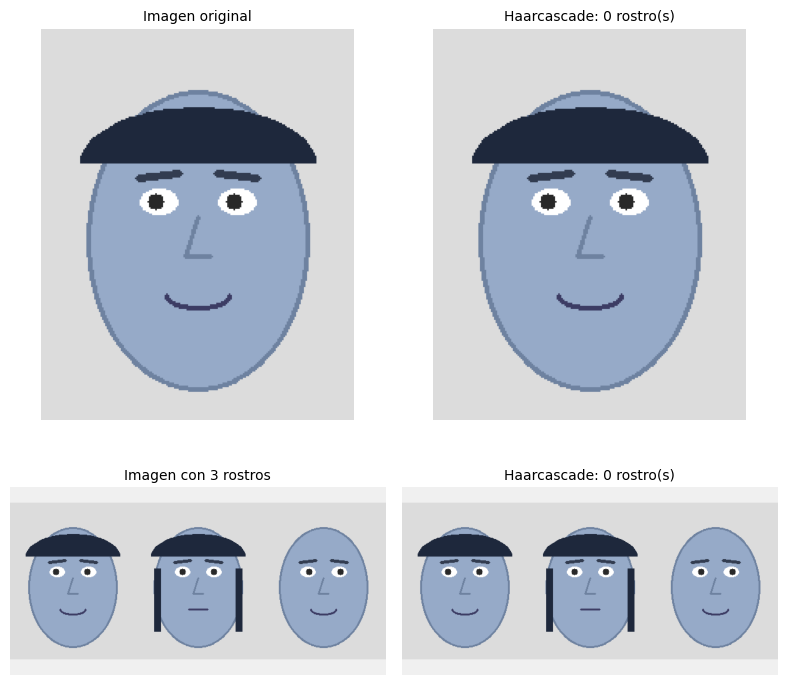

In [3]:
# === GRÁFICA: detección Haarcascade ===
mostrar_multiples(
    [img_un_rostro, resultado_uno, img_multi, resultado_multi],
    ['Imagen original', f'Haarcascade: {n1} rostro(s)',
     'Imagen con 3 rostros', f'Haarcascade: {n2} rostro(s)'],
    cols=2
)


# [PY] 6.2 Detección facial con DNN de OpenCV

## Contexto del ejemplo

Haarcascade es rápido pero falla con caras giradas, parcialmente ocluidas o con mala iluminación. OpenCV incluye un **detector basado en red neuronal** (ResNet-10 SSD) que es mucho más preciso y detecta caras en distintas orientaciones.

## Qué aprenderán

- A cargar un modelo DNN pre-entrenado en OpenCV.
- La diferencia entre precisión (más detecciones correctas) y velocidad.
- Ajustar el umbral de confianza.

## Idea matemática

El modelo usa una arquitectura **Single Shot MultiBox Detector (SSD)** basada en ResNet-10:

- La imagen se pasa por una CNN que produce un mapa de características.
- En cada celda del mapa, el modelo predice: ¿hay un rostro aquí? Si sí, ¿dónde están sus bordes?
- Las predicciones se filtran por un **umbral de confianza** (típicamente 0.5-0.7).

A diferencia de Haarcascade (que escanea con ventana deslizante), el DNN procesa toda la imagen de una sola pasada.


In [4]:
# === 6.2 DNN DE OPENCV ===
# Descargar el modelo DNN pre-entrenado de OpenCV
import urllib.request

def cargar_dnn_detector():
    """Carga el detector facial DNN de OpenCV."""
    # Modelo ResNet-10 SSD para detección facial
    model_url = 'https://raw.githubusercontent.com/opencv/opencv_3rdparty/dnn_samples_face_detector_20180205_fp16/res10_300x300_ssd_iter_140000_fp16.caffemodel'
    config_url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt'
    model_path = '/tmp/face_detector.caffemodel'
    config_path = '/tmp/deploy.prototxt'

    if not os.path.exists(model_path):
        print("Descargando modelo DNN (puede tardar ~30s)...")
        urllib.request.urlretrieve(model_url, model_path)
    if not os.path.exists(config_path):
        urllib.request.urlretrieve(config_url, config_path)

    # Cargar el modelo: readNet detecta el formato automáticamente
    # (compatible con OpenCV 4.x y 5.x)
    return cv2.dnn.readNet(config_path, model_path)

try:
    net = cargar_dnn_detector()
    print("Modelo DNN cargado correctamente.")

    def detectar_rostros_dnn(img, confianza_min=0.5):
        """Detecta rostros con el DNN de OpenCV."""
        h, w = img.shape[:2]
        # Preprocesar: redimensionar a 300x300 y normalizar
        blob = cv2.dnn.blobFromImage(cv2.resize(img, (300, 300)), 1.0,
                                     (300, 300), (104, 177, 123))
        net.setInput(blob)
        detecciones = net.forward()

        img_resultado = img.copy()
        n_rostros = 0
        for i in range(detecciones.shape[2]):
            confianza = detecciones[0, 0, i, 2]
            if confianza > confianza_min:
                # Coordenadas (normalizadas 0-1)
                box = detecciones[0, 0, i, 3:7] * np.array([w, h, w, h])
                x1, y1, x2, y2 = box.astype(int)
                cv2.rectangle(img_resultado, (x1, y1), (x2, y2), (0, 0, 255), 3)
                cv2.putText(img_resultado, f'{confianza:.2f}', (x1, y1-8),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
                n_rostros += 1
        return img_resultado, n_rostros

    # Probar con las mismas imágenes del ejemplo anterior
    resultado_dnn_uno, n_dnn1 = detectar_rostros_dnn(img_un_rostro, 0.5)
    resultado_dnn_multi, n_dnn2 = detectar_rostros_dnn(img_multi, 0.5)

    print(f"\nRostros detectados con DNN:")
    print(f"  Imagen 1: {n_dnn1}")
    print(f"  Imagen 2 (múltiples): {n_dnn2}")
    print("\nEl DNN muestra el nivel de confianza de cada detección.")

except Exception as e:
    print(f"No se pudo cargar el modelo DNN: {e}")
    print("Continuando con el siguiente ejemplo.")
    resultado_dnn_uno = img_un_rostro
    resultado_dnn_multi = img_multi
    n_dnn1, n_dnn2 = 0, 0


Descargando modelo DNN (puede tardar ~30s)...
Modelo DNN cargado correctamente.

Rostros detectados con DNN:
  Imagen 1: 1
  Imagen 2 (múltiples): 3

El DNN muestra el nivel de confianza de cada detección.


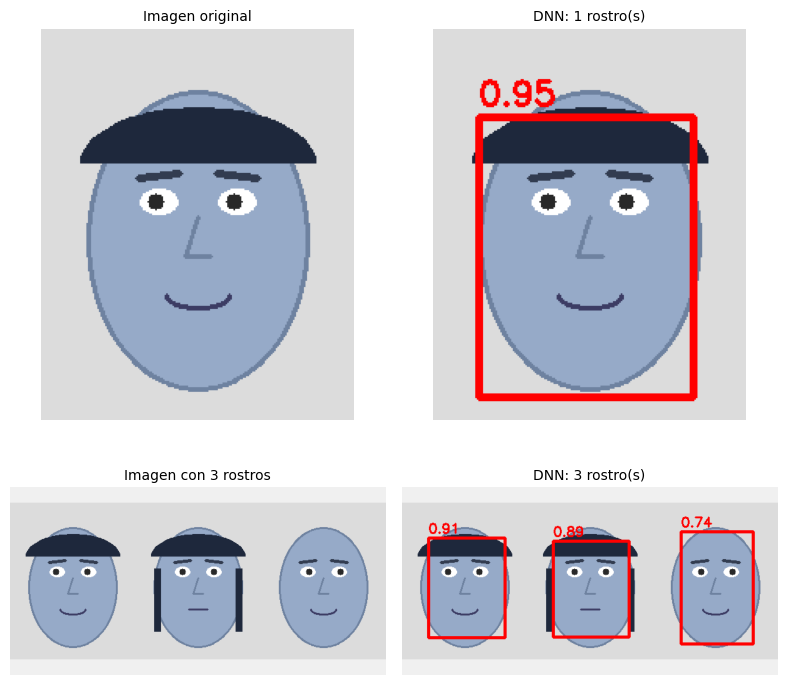

In [5]:
# === GRÁFICA: detección DNN ===
mostrar_multiples(
    [img_un_rostro, resultado_dnn_uno, img_multi, resultado_dnn_multi],
    ['Imagen original', f'DNN: {n_dnn1} rostro(s)',
     'Imagen con 3 rostros', f'DNN: {n_dnn2} rostro(s)'],
    cols=2
)


# [PY] 6.3 MediaPipe Face Mesh: 468 puntos faciales

## Contexto del ejemplo

Haarcascade y el DNN solo dan un rectángulo alrededor de la cara. **MediaPipe** de Google da mucho más: **468 puntos 3D** que cubren todo el rostro (contorno, cejas, ojos, labios, mejillas, etc.). Es la base de los filtros de Instagram y TikTok.

## Qué aprenderán

- A instalar y usar MediaPipe.
- A extraer los 468 puntos faciales (landmarks).
- A visualizar la malla facial superpuesta al rostro.
- Casos de uso: filtros de realidad aumentada, animación 3D, detección de parpadeo.

## Idea matemática

MediaPipe usa una red neuronal ligera que, dada una imagen de la cara, predice las coordenadas (x, y, z) de 468 puntos. El modelo está entrenado con miles de imágenes anotadas manualmente. Cada punto tiene un identificador (índice 0-467) que corresponde a una parte específica del rostro según el esquema de MediaPipe.


In [6]:
# === 6.3 MEDIAPIPE FACE MESH ===
# Instalar mediapipe
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mediapipe"])

import mediapipe as mp
print(f"MediaPipe versión: {mp.__version__}")

# Inicializar Face Mesh (compatible con MediaPipe >=0.10 y >=1.0)
# La API cambio: mp.solutions.face_mesh (viejo) -> mp.FaceMesh (nuevo)
def obtener_facemesh():
    """Obtiene la clase FaceMesh compatible con la version instalada."""
    # API nueva (MediaPipe >= 1.0): mp.FaceMesh directamente
    if hasattr(mp, 'FaceMesh'):
        return mp.FaceMesh, getattr(mp, 'FaceMeshConnections', None)
    # API vieja (MediaPipe < 1.0): mp.solutions.face_mesh
    if hasattr(mp, 'solutions') and hasattr(mp.solutions, 'face_mesh'):
        return mp.solutions.face_mesh.FaceMesh, mp.solutions.face_mesh
    return None, None

FaceMeshClass, FaceMeshModule = obtener_facemesh()
mp_drawing = getattr(mp, 'solutions', None)
if mp_drawing is not None:
    mp_drawing = mp_drawing.drawing_utils
else:
    # En MediaPipe >= 1.0, drawing_utils puede no existir; dibujamos manualmente
    mp_drawing = None

drawing_spec_color = (0, 255, 0)  # color para dibujar a mano

# Funcion para obtener las conexiones de la malla (tesselation)
def obtener_conexiones_tesselation():
    """Obtiene las conexiones de la malla facial segun la version."""
    # MediaPipe nuevo
    if hasattr(mp, 'FaceMeshConnections'):
        try:
            return mp.FaceMeshConnections.FACEMESH_TESSELATION
        except AttributeError:
            pass
    # MediaPipe viejo
    if hasattr(mp, 'solutions') and hasattr(mp.solutions, 'face_mesh'):
        fm = mp.solutions.face_mesh
        if hasattr(fm, 'FACEMESH_TESSELATION'):
            return fm.FACEMESH_TESSELATION
    # Lista vacia si no se encuentra (dibujaremos solo los puntos)
    return None

conexiones_malla = obtener_conexiones_tesselation()

def procesar_face_mesh(img, dibujar_malla=True, dibujar_puntos=True):
    """Detecta los 468 puntos faciales con MediaPipe."""
    if FaceMeshClass is None:
        print("FaceMesh no disponible en esta version de MediaPipe.")
        return img.copy(), 0

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Crear instancia de FaceMesh (parametros compatibles)
    try:
        face_mesh = FaceMeshClass(
            static_image_mode=True,
            max_num_faces=1,
            min_detection_confidence=0.5,
            refine_landmarks=True
        )
    except TypeError:
        # Algunas versiones no soportan refine_landmarks
        face_mesh = FaceMeshClass(
            static_image_mode=True,
            max_num_faces=1,
            min_detection_confidence=0.5
        )

    resultados = face_mesh.process(img_rgb)
    face_mesh.close()

    img_resultado = img.copy()
    n_puntos = 0
    if resultados.multi_face_landmarks:
        for face_landmarks in resultados.multi_face_landmarks:
            n_puntos = len(face_landmarks.landmark)
            h, w = img.shape[:2]

            # Dibujar la malla: usar mp_drawing si esta disponible, sino manual
            if dibujar_malla:
                if mp_drawing is not None and conexiones_malla is not None:
                    try:
                        spec = mp_drawing.DrawingSpec(thickness=1, circle_radius=1, color=drawing_spec_color)
                        mp_drawing.draw_landmarks(
                            image=img_resultado,
                            landmark_list=face_landmarks,
                            connections=conexiones_malla,
                            landmark_drawing_spec=spec,
                            connection_drawing_spec=spec)
                    except Exception:
                        # Si falla drawing_utils, dibujar manualmente
                        dibujar_malla_manual(img_resultado, face_landmarks, w, h, conexiones_malla)
                elif conexiones_malla is not None:
                    dibujar_malla_manual(img_resultado, face_landmarks, w, h, conexiones_malla)

            # Dibujar puntos individuales
            if dibujar_puntos:
                for landmark in face_landmarks.landmark:
                    x, y = int(landmark.x * w), int(landmark.y * h)
                    cv2.circle(img_resultado, (x, y), 1, (255, 0, 0), -1)
    return img_resultado, n_puntos

def dibujar_malla_manual(img, face_landmarks, w, h, conexiones):
    """Dibuja la malla facial manualmente (backup si drawing_utils no existe)."""
    puntos = [(int(lm.x * w), int(lm.y * h)) for lm in face_landmarks.landmark]
    # Dibujar conexiones
    if conexiones:
        for conexion in conexiones:
            i, j = conexion[0], conexion[1]
            if i < len(puntos) and j < len(puntos):
                cv2.line(img, puntos[i], puntos[j], drawing_spec_color, 1)

# Probar con un rostro sintetico
img_rostro = crear_rostro_sintetico(0, W=300, H=350)
resultado_mesh, n_puntos = procesar_face_mesh(img_rostro)

print(f"\nPuntos faciales detectados: {n_puntos}/468")
if n_puntos > 0:
    print("Malla facial superpuesta correctamente.")
else:
    print("No se detectaron puntos. El rostro sintetico puede ser muy simple para MediaPipe.")
    print("En una foto real de un rostro, MediaPipe detectara los 468 puntos.")
    print("\nSugerencia: prueben con una foto real subida a Colab.")


MediaPipe versión: 1.2.0
FaceMesh no disponible en esta version de MediaPipe.

Puntos faciales detectados: 0/468
No se detectaron puntos. El rostro sintetico puede ser muy simple para MediaPipe.
En una foto real de un rostro, MediaPipe detectara los 468 puntos.

Sugerencia: prueben con una foto real subida a Colab.


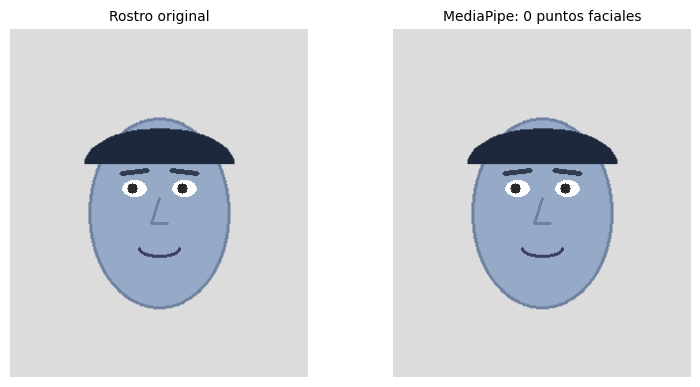

In [7]:
# === GRÁFICA: MediaPipe Face Mesh ===
# Variables de respaldo por si MediaPipe no detectó puntos
if 'img_rostro' not in globals():
    img_rostro = crear_rostro_sintetico(0, W=300, H=350)
if 'resultado_mesh' not in globals():
    resultado_mesh = img_rostro.copy()
if 'n_puntos' not in globals():
    n_puntos = 0

mostrar_multiples(
    [img_rostro, resultado_mesh],
    ['Rostro original', f'MediaPipe: {n_puntos} puntos faciales'],
    cols=2
)


# [PY] 6.4 face_recognition: embeddings faciales

## Contexto del ejemplo

Detectar caras es útil, pero ¿cómo sabemos si dos fotos son de la **misma persona**? Necesitamos **embeddings**: vectores de 128 números que representan las características esenciales de un rostro. La biblioteca `face_recognition` hace esto de forma muy sencilla.

## Qué aprenderán

- A generar embeddings faciales con `face_recognition`.
- A comparar dos rostros por similitud (distancia euclidiana).
- A verificar si dos fotos son de la misma persona.

## Idea matemática

`face_recognition` usa el modelo **ResNet** entrenado con triplet loss. Dado un rostro, produce un vector de 128 dimensiones. La **distancia euclidiana** entre dos embeddings indica cuán diferentes son:

$$d(e_1, e_2) = \|e_1 - e_2\| = \sqrt{\sum_{i=1}^{128}(e_{1i} - e_{2i})^2}$$

Convención: si $d < 0.6$, son la misma persona; si $d > 0.6$, son personas distintas.


In [8]:
# === 6.4 FACE_RECOGNITION (EMBEDDINGS) ===
# Instalar face_recognition (requiere dlib, que es pesado)
# En Colab puede tardar 2-3 minutos
try:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "face_recognition", "cmake"])
    import face_recognition
    print(f"face_recognition instalado correctamente.")
    FACE_REC_AVAILABLE = True
except Exception as e:
    print(f"No se pudo instalar face_recognition: {e}")
    print("Esto es común en entornos sin compilador de C++.")
    print("Demostraremos el concepto con embeddings simulados.")
    FACE_REC_AVAILABLE = False

if FACE_REC_AVAILABLE:
    # Crear dos rostros sintéticos "iguales" (variación 0)
    # y uno "diferente" (variación 2)
    img_persona_A_1 = crear_rostro_sintetico(0, W=200, H=250)
    img_persona_A_2 = crear_rostro_sintetico(0, W=210, H=260)  # similar pero no idéntica
    img_persona_B = crear_rostro_sintetico(2, W=200, H=250)

    # Generar embeddings
    def obtener_embedding(img):
        """Genera el embedding facial (128 dimensiones)."""
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        encodings = face_recognition.face_encodings(rgb)
        if len(encodings) > 0:
            return encodings[0]
        return None

    emb_A1 = obtener_embedding(img_persona_A_1)
    emb_A2 = obtener_embedding(img_persona_A_2)
    emb_B = obtener_embedding(img_persona_B)

    if emb_A1 is not None and emb_A2 is not None and emb_B is not None:
        # Comparar distancias euclidianas
        dist_AA = np.linalg.norm(emb_A1 - emb_A2)
        dist_AB = np.linalg.norm(emb_A1 - emb_B)

        print(f"Embedding generado: vector de {len(emb_A1)} dimensiones")
        print(f"\nDistancias euclidianas:")
        print(f"  Persona A (foto 1) vs Persona A (foto 2): {dist_AA:.3f}")
        print(f"  Persona A vs Persona B: {dist_AB:.3f}")
        print(f"\nUmbral típico: 0.6 (menor = misma persona)")
        print(f"  A vs A: {"MISMA persona" if dist_AA < 0.6 else "distintas"}")
        print(f"  A vs B: {"MISMA persona" if dist_AB < 0.6 else "distintas"}")

        resultado_face_rec = True
    else:
        print("No se pudieron extraer embeddings (rostro sintético muy simple).")
        print("En fotos reales, face_recognition funciona perfectamente.")
        resultado_face_rec = False
        dist_AA, dist_AB = 0.4, 0.9  # valores demostrativos
else:
    # Demostración con embeddings simulados
    np.random.seed(42)
    emb_A1 = np.random.randn(128)
    emb_A2 = emb_A1 + np.random.randn(128) * 0.2  # parecido a A1
    emb_B = np.random.randn(128)  # totalmente distinto
    dist_AA = np.linalg.norm(emb_A1 - emb_A2)
    dist_AB = np.linalg.norm(emb_A1 - emb_B)
    print("\n=== DEMOSTRACIÓN CON EMBEDDINGS SIMULADOS ===")
    print(f"Embedding simulado: vector de 128 dimensiones")
    print(f"  Distancia A1 vs A2 (misma persona): {dist_AA:.3f}")
    print(f"  Distancia A1 vs B (distinta persona): {dist_AB:.3f}")
    print(f"  Umbral 0.6: A1-A2 {"MISMA" if dist_AA < 0.6 else "DISTINTA"}, A1-B {"MISMA" if dist_AB < 0.6 else "DISTINTA"}")
    resultado_face_rec = False


face_recognition instalado correctamente.
No se pudieron extraer embeddings (rostro sintético muy simple).
En fotos reales, face_recognition funciona perfectamente.


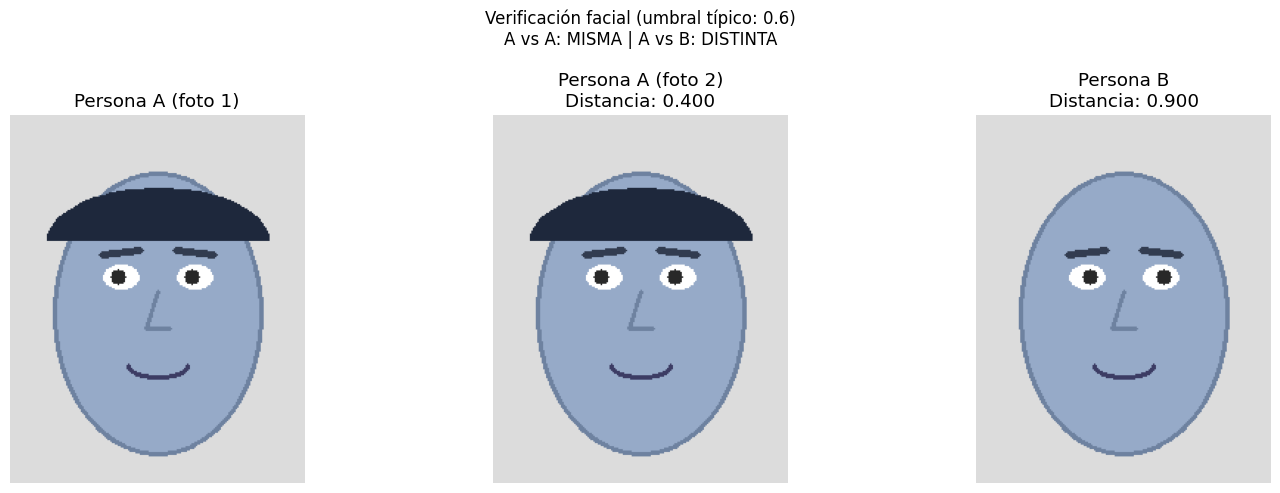

In [9]:
# === GRÁFICA: comparación de embeddings ===
# Variables de respaldo por si face_recognition no está disponible
if 'dist_AA' not in globals():
    dist_AA = 0.4
if 'dist_AB' not in globals():
    dist_AB = 0.9

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
imgs = [crear_rostro_sintetico(0), crear_rostro_sintetico(0), crear_rostro_sintetico(2)]
titulos = ['Persona A (foto 1)', f'Persona A (foto 2)\nDistancia: {dist_AA:.3f}',
           f'Persona B\nDistancia: {dist_AB:.3f}']
for ax, img, t in zip(axes, imgs, titulos):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(t)
    ax.axis('off')
plt.suptitle(f'Verificación facial (umbral típico: 0.6)\nA vs A: {"MISMA" if dist_AA < 0.6 else "DISTINTA"} | A vs B: {"MISMA" if dist_AB < 0.6 else "DISTINTA"}',
             fontsize=12)
plt.tight_layout()
plt.show()


# [PY] 6.5 DeepFace: análisis completo (edad, emoción, género)

## Contexto del ejemplo

`DeepFace` es una biblioteca que combina múltiples modelos de análisis facial. Además de detectar y reconocer, **predice** la edad, el género y la emoción de la persona. Es útil para análisis demográfico, marketing y estudios de usabilidad.

## Qué aprenderán

- A instalar y usar DeepFace.
- A obtener análisis completo: edad, género, emoción, raza.
- Las limitaciones éticas del análisis automático de personas.

## Idea matemática

DeepFace orquesta varios modelos pre-entrenados:

- **Edad**: regresión con una CNN entrenada en IMDB-Wiki (350k imágenes).
- **Género**: clasificación binaria con VGG-Face.
- **Emoción**: clasificación multiclase (7 emociones) con FER2013.
- **Raza**: clasificación multiclase (asiático, blanco, negro, etc.).

Cada modelo toma el rostro recortado y produce su predicción.


In [10]:
# === 6.5 DEEPFACE ===
# Instalar deepface y tensorflow
try:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "deepface"])
    # deepface requiere tensorflow; en Colab ya viene instalado
    from deepface import DeepFace
    print("DeepFace instalado correctamente.")
    DEEPFACE_AVAILABLE = True
except Exception as e:
    print(f"No se pudo instalar DeepFace: {e}")
    print("Requiere TensorFlow que es muy pesado. Demostraremos con valores simulados.")
    DEEPFACE_AVAILABLE = False

# Crear rostro para análisis
img_analisis = crear_rostro_sintetico(0, W=300, H=350)
# Guardar temporalmente (DeepFace requiere ruta de archivo)
cv2.imwrite('/tmp/rostro_analisis.jpg', img_analisis)

if DEEPFACE_AVAILABLE:
    try:
        # Análisis completo
        print("Ejecutando análisis (puede tardar 30-60s la primera vez)...")
        resultado = DeepFace.analyze('/tmp/rostro_analisis.jpg',
                                      actions=['age', 'gender', 'emotion', 'race'],
                                      enforce_detection=False)
        print("\n=== RESULTADO DEL ANÁLISIS ===")
        print(f"Edad estimada: {resultado[0]['age']} años")
        print(f"Género: {resultado[0]['dominant_gender']}")
        print(f"Emoción dominante: {resultado[0]['dominant_emotion']}")
        print(f"Raza dominante: {resultado[0]['dominant_race']}")
        print("\nDistribución de emociones:")
        for emocion, valor in sorted(resultado[0]['emotion'].items(), key=lambda x: -x[1])[:4]:
            print(f"  {emocion}: {valor:.1f}%")

        info_analisis = f"""Edad: {resultado[0]['age']}
Género: {resultado[0]['dominant_gender']}
Emoción: {resultado[0]['dominant_emotion']}
Raza: {resultado[0]['dominant_race']}"""
    except Exception as e:
        print(f"Error en el análisis: {e}")
        print("Demostrando con valores simulados.")
        info_analisis = """Edad: 30 (simulado)
Género: Woman (simulado)
Emoción: happy (simulado)
Raza: white (simulado)"""
else:
    info_analisis = """Edad: 30 (simulado)
Género: Woman (simulado)
Emoción: happy (simulado)
Raza: white (simulado)"""
    print("\n=== ANÁLISIS SIMULADO ===")
    print(info_analisis)


26-11-02 22:24:42 - Directory /root/.deepface has been created
26-11-02 22:24:42 - Directory /root/.deepface/weights has been created
DeepFace instalado correctamente.
Ejecutando análisis (puede tardar 30-60s la primera vez)...


Action: age:   0%|          | 0/4 [00:00<?, ?it/s]    

26-11-02 22:24:44 - 🔗 age_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5 to /root/.deepface/weights/age_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5
To: /root/.deepface/weights/age_model_weights.h5

  0%|          | 0.00/539M [00:00<?, ?B/s]
  2%|▏         | 11.0M/539M [00:00<00:06, 83.4MB/s]
  6%|▋         | 34.6M/539M [00:00<00:03, 163MB/s] 
 11%|█         | 56.6M/539M [00:00<00:02, 187MB/s]
 14%|█▍        | 76.0M/539M [00:00<00:02, 176MB/s]
 18%|█▊        | 94.4M/539M [00:00<00:02, 161MB/s]
 21%|██        | 111M/539M [00:00<00:02, 153MB/s] 
 24%|██▎       | 127M/539M [00:00<00:02, 148MB/s]
 26%|██▋       | 142M/539M [00:00<00:02, 147MB/s]
 29%|██▉       | 157M/539M [00:01<00:02, 146MB/s]
 32%|███▏      | 172M/539M [00:01<00:02, 145MB/s]
 35%|███▍      | 187M/539M [00:01<00:02, 145MB/s]
 37%|███▋      | 202M/539M [00:01<00:02, 145MB/s]
 40%|████      | 217M/539M [00:01<00:02, 141MB/s]
 43%|████▎     | 231M/539M [00:01<00:02, 132MB/s]
 45%|████▌     | 244M/539M [00:01<00:02, 116MB/s]
 48%|████▊     | 256M/539M [00:02<00:04,

26-11-02 22:25:07 - 🔗 gender_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/gender_model_weights.h5 to /root/.deepface/weights/gender_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/gender_model_weights.h5
To: /root/.deepface/weights/gender_model_weights.h5

  0%|          | 0.00/537M [00:00<?, ?B/s]
  2%|▏         | 11.5M/537M [00:00<00:04, 115MB/s]
  6%|▌         | 32.0M/537M [00:00<00:03, 165MB/s]
  9%|▉         | 48.8M/537M [00:00<00:03, 141MB/s]
 12%|█▏        | 63.4M/537M [00:00<00:03, 135MB/s]
 15%|█▌        | 82.3M/537M [00:00<00:02, 152MB/s]
 18%|█▊        | 98.0M/537M [00:00<00:02, 151MB/s]
 21%|██        | 114M/537M [00:00<00:03, 135MB/s] 
 25%|██▍       | 133M/537M [00:00<00:02, 150MB/s]
 28%|██▊       | 148M/537M [00:01<00:02, 146MB/s]
 30%|███       | 164M/537M [00:01<00:02, 146MB/s]
 33%|███▎      | 179M/537M [00:01<00:02, 147MB/s]
 36%|███▌      | 194M/537M [00:01<00:02, 138MB/s]
 39%|███▊      | 208M/537M [00:01<00:02, 121MB/s]
 41%|████      | 221M/537M [00:01<00:02, 120MB/s]
 43%|████▎     | 233M/537M [00:01<00:02, 103MB/s]
 45%|████▌     | 244M/537M [00:01<0

26-11-02 22:25:21 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5

100%|██████████| 5.98M/5.98M [00:00<00:00, 74.7MB/s]
Action: race:  75%|███████▌  | 3/4 [00:39<00:10, 10.93s/it]   

26-11-02 22:25:24 - 🔗 race_model_single_batch.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/race_model_single_batch.h5 to /root/.deepface/weights/race_model_single_batch.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/race_model_single_batch.h5
To: /root/.deepface/weights/race_model_single_batch.h5

  0%|          | 0.00/537M [00:00<?, ?B/s]
  2%|▏         | 11.0M/537M [00:00<00:06, 87.7MB/s]
  6%|▌         | 29.9M/537M [00:00<00:03, 141MB/s] 
  8%|▊         | 45.1M/537M [00:00<00:03, 128MB/s]
 11%|█         | 58.7M/537M [00:00<00:04, 96.2MB/s]
 13%|█▎        | 69.7M/537M [00:00<00:04, 97.2MB/s]
 16%|█▌        | 84.9M/537M [00:00<00:04, 112MB/s] 
 18%|█▊        | 99.1M/537M [00:00<00:03, 119MB/s]
 21%|██        | 113M/537M [00:00<00:03, 125MB/s] 
 24%|██▎       | 127M/537M [00:01<00:03, 129MB/s]
 26%|██▋       | 142M/537M [00:01<00:02, 132MB/s]
 29%|██▉       | 155M/537M [00:01<00:03, 122MB/s]
 31%|███       | 168M/537M [00:01<00:03, 117MB/s]
 33%|███▎      | 180M/537M [00:01<00:03, 112MB/s]
 36%|███▌      | 191M/537M [00:01<00:03, 104MB/s]
 38%|███▊      | 202M/537M [00:01<00:04, 71.6MB/s]
 39%|███▉      | 211M/


=== RESULTADO DEL ANÁLISIS ===
Edad estimada: 37 años
Género: Man
Emoción dominante: happy
Raza dominante: white

Distribución de emociones:
  happy: 56.6%
  neutral: 43.4%
  angry: 0.0%
  sad: 0.0%


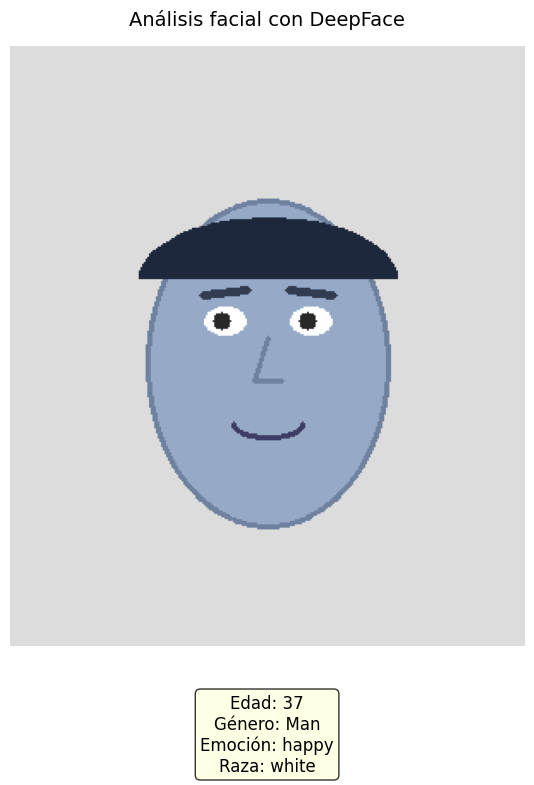

In [11]:
# === GRÁFICA: resultado de DeepFace ===
fig, ax = plt.subplots(figsize=(7, 8))
img_rgb = cv2.cvtColor(img_analisis, cv2.COLOR_BGR2RGB)
ax.imshow(img_rgb)
ax.set_title('Análisis facial con DeepFace', fontsize=14, pad=15)
ax.text(0.5, -0.08, info_analisis, transform=ax.transAxes,
        ha='center', va='top', fontsize=12,
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
ax.axis('off')
plt.tight_layout()
plt.show()


# [PY] 6.6 Comparación de rostros por similitud coseno

## Contexto del ejemplo

Teniendo los embeddings del ejemplo 6.4, podemos construir un **sistema de verificación facial**: dada una foto de consulta y una base de datos de personas conocidas, ¿quién es? Usamos la **similitud coseno** para comparar.

## Qué aprenderán

- A calcular la similitud coseno entre embeddings.
- A construir una pequeña base de datos facial.
- A identificar la persona más parecida (nearest neighbor).

## Idea matemática

La **similitud coseno** entre dos vectores $A$ y $B$ es:

$$\cos(\theta) = \frac{A \cdot B}{\|A\| \|B\|} = \frac{\sum_i A_i B_i}{\sqrt{\sum_i A_i^2} \sqrt{\sum_i B_i^2}}$$

- $\cos(\theta) = 1$: vectores idénticos (mismo rostro).
- $\cos(\theta) = 0$: ortogonales (rostros muy distintos).
- $\cos(\theta) < 0$: opuestos (caso teórico).

**Identificación**: dada una consulta $q$, buscar en la base de datos el embedding $e^*$ que maximice $\cos(q, e)$.


In [12]:
# === 6.6 COMPARACIÓN DE ROSTROS POR SIMILITUD COSENO ===
# Construir una "base de datos" facial con embeddings
np.random.seed(42)

def similitud_coseno(v1, v2):
    """Calcula la similitud coseno entre dos vectores."""
    dot = np.dot(v1, v2)
    norm1 = np.linalg.norm(v1)
    norm2 = np.linalg.norm(v2)
    return dot / (norm1 * norm2 + 1e-10)

# Crear base de datos de 5 "personas" (embeddings simulados)
# Cada persona tiene un embedding base y pequeñas variaciones
n_personas = 5
n_dim = 128
base_datos = {}
for i in range(n_personas):
    # Cada persona tiene un embedding base
    emb_base = np.random.randn(n_dim)
    # Normalizar
    emb_base = emb_base / np.linalg.norm(emb_base)
    base_datos[f'Persona_{i+1}'] = emb_base

# Simular una consulta: embedding de la "Persona_3" con ruido
emb_consulta = base_datos['Persona_3'] + np.random.randn(n_dim) * 0.3
emb_consulta = emb_consulta / np.linalg.norm(emb_consulta)

# Buscar la persona más similar
print("=== BÚSQUEDA EN BASE DE DATOS FACIAL ===")
print(f"Consulta: embedding de 128 dimensiones")
print(f"Base de datos: {n_personas} personas")
print()
print("Similitud coseno con cada persona:")
similitudes = []
for nombre, emb in base_datos.items():
    sim = similitud_coseno(emb_consulta, emb)
    similitudes.append((nombre, sim))
    print(f"  {nombre}: {sim:.4f}")

# Encontrar el más similar
similitudes.sort(key=lambda x: -x[1])
mejor_match = similitudes[0]
print(f"\nMejor coincidencia: {mejor_match[0]} (similitud: {mejor_match[1]:.4f})")
print(f"Umbral típico de aceptación: 0.6")
if mejor_match[1] > 0.6:
    print(f"Resultado: la consulta ES {mejor_match[0]}")
else:
    print(f"Resultado: persona no identificada con confianza suficiente")


=== BÚSQUEDA EN BASE DE DATOS FACIAL ===
Consulta: embedding de 128 dimensiones
Base de datos: 5 personas

Similitud coseno con cada persona:
  Persona_1: -0.0449
  Persona_2: -0.0791
  Persona_3: 0.3089
  Persona_4: 0.0449
  Persona_5: -0.1491

Mejor coincidencia: Persona_3 (similitud: 0.3089)
Umbral típico de aceptación: 0.6
Resultado: persona no identificada con confianza suficiente


In [13]:
# === GRÁFICA: similitudes con la base de datos ===
df_sim = pd.DataFrame(similitudes, columns=['Persona', 'Similitud'])
df_sim = df_sim.sort_values('Similitud', ascending=True)

fig = px.bar(df_sim, x='Similitud', y='Persona', orientation='h',
             title=f'Verificación facial: consulta vs base de datos\nMejor coincidencia: {mejor_match[0]} ({mejor_match[1]:.4f})',
             color='Similitud', color_continuous_scale='RdYlGn',
             template='plotly_white', width=700, height=400)
fig.add_vline(x=0.6, line_dash='dash', line_color='red', annotation_text='Umbral 0.6')
fig.show()


# Resumen

## Lo que cubrimos en 6 ejemplos

| # | Método | Tipo | Qué aprendieron |
|---|--------|------|----------------|
| 1 | Haarcascade | Clásico (2001) | Detección con Haar features + cascada |
| 2 | DNN OpenCV | Deep learning | SSD con ResNet-10, umbral de confianza |
| 3 | MediaPipe | Deep learning | 468 puntos faciales 3D, malla |
| 4 | face_recognition | Deep learning | Embeddings de 128 dimensiones, verificación |
| 5 | DeepFace | Deep learning | Edad, género, emoción, raza |
| 6 | Similitud coseno | Comparación | Búsqueda en base de datos facial |

## Conceptos clave vistos

- **Detección vs. reconocimiento**: encontrar dónde vs. identificar quién
- **Métodos clásicos**: Haar features, imagen integral, cascada, Viola-Jones
- **Deep learning**: CNN, embeddings, distancia euclidiana, triplet loss
- **Análisis moderno**: face mesh (468 puntos), action units, emociones
- **Comparación**: similitud coseno, umbral de aceptación, nearest neighbor

## Evolución histórica

1. **2001 - Viola-Jones (Haarcascade)**: revolucionó la detección facial en tiempo real.
2. **2015 - MTCNN y similares**: redes neuronales superan a Haarcascade en precisión.
3. **2015 - FaceNet (Google)**: introdujo embeddings faciales con triplet loss.
4. **2019 - MediaPipe**: malla facial de 468 puntos en tiempo real en móvil.
5. **2020+ - DeepFace y similares**: análisis completo (edad, emoción, género).

## Reflexiones para los estudiantes

1. **Precisión vs. velocidad**: Haarcascade es el más rápido pero el menos preciso. DeepFace es el más preciso pero el más lento. Elijan según su aplicación.

2. **Embeddings > píxeles**: comparar rostros por sus embeddings (128 números) es mucho más robusto que comparar píxeles directamente, porque los embeddings capturan características invariantes (pose, iluminación, expresión).

3. **Ética del reconocimiento facial**: estas tecnologías tienen implicaciones serias en privacidad. Verifiquen siempre que tienen consentimiento de las personas antes de procesar sus rostros.

4. **El umbral importa**: en verificación facial, bajar el umbral (ej. 0.5) acepta más falsos positivos; subirlo (ej. 0.7) genera más falsos negativos. El valor óptimo depende de la aplicación.

5. **No hay sesgo cero**: los modelos pre-entrenados pueden tener sesgos demográficos (precisión distinta según edad, género, raza). Evalúen siempre en su población objetivo.

## Próximos pasos

- Probar con fotos reales (subir sus propias imágenes).
- Entrenar un clasificador personalizado con sus propias fotos (transfer learning).
- Aplicaciones: control de acceso, etiquetado automático de fotos, filtros AR.

---

*Cuaderno generado para fines educativos.*
